# Calculating and comparing Wavelength exponent 

This analytical notebook belongs to the original [PorosityP repository](https://github.com/IbragimovAlmaz/PorosityP), alongside other Python scripts for the data processing and plotting. This codebase contains modifications to reproduce the results of the article *Correlating Emulsion Optical Properties with the Percolation in Solvent-Cast PLA/PVP Membranes*, and requires the data within GitHub and Zenodo repositories, alongside custom processing and visualization scripts.

# Getting Started

Follow these steps to set up your local Python environment and install all required dependencies.


### Installing Dependencies

Install the core libraries via `pip`.
```bash
pip install numpy pandas scikit-learn scipy pingouin scikit-posthocs statannotations matplotlib seaborn plotly
```

Alternatively, according to the `requirements.txt` file in the same directory, you can run:
```bash
pip install -r requirements.txt
```

*Note: If you are running this directly inside a Jupyter notebook cell, use the `%pip` command (`%pip install -r requirements.txt`) to ensure it installs into the correct kernel.*

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import matplotlib as mtl
import pingouin as pg
import numpy as np
import scipy.stats as stats
from pylab import rcParams
import scikit_posthocs as sp
import pandas as pd

C:\Users\Serpenticor\AppData\Roaming\Python\Python39\site-packages\pandas\core\computation\expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Serpenticor\AppData\Roaming\Python\Python39\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.4' currently installed).
  from pandas.core import (


In [2]:
# Ångström exponent / Wavelength exponent / Scattering exponent / Turbidity exponent (same names) data
pla85 = np.array([2.0332465737611463, 2.040067973920987, 2.083491645708221, 
                  2.288049113075093, 2.526971760100247, 2.308813518297431,
                 2.466435014140157, 2.5083619945928683, 2.795211917317264])

pla80 = np.array([1.8567672315528252, 1.8400928549570925, 1.824675898994074,
                 1.7475888139577131, 1.776024031370987, 1.7698488833894777,
                 1.9320434515525349, 1.9164805765405457, 1.9085867456386156])

pla75 = np.array([0.3624460867777561, 0.35054067608716116, 0.34978622198000187,
                 0.27147678259927327, 0.26816854837672327, 0.2631683408798032,
                 0.3724881947785119, 0.37151435646247716, 0.36832339194170477])

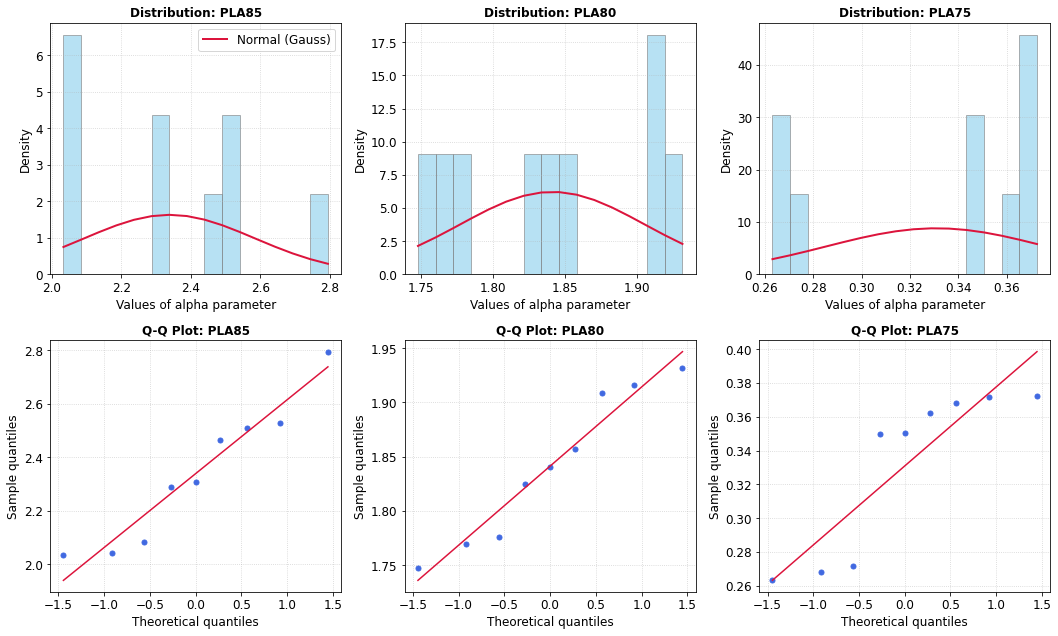

In [3]:
# 1. Loading the data for the preliminary distribution analysis
datasets = {"PLA85": pla85, "PLA80": pla80, "PLA75": pla75}

# 2. Setting the fonts
plt.rcParams.update({"font.size": 12, "font.family": "sans-serif"})

# 3. Making the grid: 2 rows (Histograms and Q-Q plots), 3 columns (groups)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i, (name, data) in enumerate(datasets.items()):
    # ---- Top panel: Histogram + Density curve ----
    ax_hist = axes[0, i]
    # Making the histogram by matplotlib/scipy
    count, bins, ignored = ax_hist.hist(
        data, bins=15, density=True, alpha=0.6, color="skyblue", edgecolor="gray"
    )

    # Applying a theoretically correct normal distribution curve for comparisons
    mu, sigma = np.mean(data), np.std(data)
    ax_hist.plot(
        bins,
        1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(-((bins - mu) ** 2) / (2 * sigma**2)),
        linewidth=2,
        color="crimson",
        label="Normal (Gauss)",
    )

    ax_hist.set_title(f"Distribution: {name}", fontsize=12, fontweight="bold")
    ax_hist.set_xlabel("Values of alpha parameter")
    ax_hist.set_ylabel("Density")
    ax_hist.grid(True, linestyle=":", alpha=0.6)
    if i == 0:
        ax_hist.legend()

    # ---- Bottom panel: the Q-Q Plot ----
    ax_qq = axes[1, i]
    stats.probplot(data, dist="norm", plot=ax_qq)

    # Visual corrections of the Q-Q plot
    ax_qq.get_lines()[0].set_color("royalblue")  # Dots color
    ax_qq.get_lines()[0].set_markersize(5)
    ax_qq.get_lines()[1].set_color("crimson")  # The slope color

    ax_qq.set_title(f"Q-Q Plot: {name}", fontsize=12, fontweight="bold")
    ax_qq.set_xlabel("Theoretical quantiles")
    ax_qq.set_ylabel("Sample quantiles")
    ax_qq.grid(True, linestyle=":", alpha=0.6)

# Subplots layout
plt.tight_layout()

# 4. Saving the figure if neccessary
#plt.savefig("alpha_distribution_analysis.png", dpi=300, bbox_inches="tight")
#print("Saved as 'alpha_distribution_analysis.png', 300 DPI.")

plt.show()

### Statistical Pipeline for Multi-Group Analysis

This pipeline automatically tests statistical assumptions and chooses between parametric or non-parametric test paths.

#### **Step 1: Data Preparation & Normality Testing**
* **Data Consolidation**: Merges target emulsion groups (`PLA85`, `PLA80`, `PLA75`) into a unified DataFrame.
* **Normality Check**: Runs the Shapiro-Wilk test on each experimental group.

#### **Step 2: Conditional Analysis Path Selection**

* **Path A: Parametric Testing** (If all groups are normally distributed, $p > 0.05$)
    1. **Levene’s Test**: Verifies the homogeneity of variances.
    2. **One-Way ANOVA**: Evaluates global variance across groups and reports **Partial $\eta^2$ (Partial Eta-Squared)** (`np2`) for global effect size.
    3. **Tukey’s HSD Post-hoc**: Computes pairwise comparisons and outputs **Hedges' $g$ / Cohen's $d$** for standardized pairwise effect sizes.

* **Path B: Non-Parametric Testing** (If any group violates normality, $p \le 0.05$)
    1. **Kruskal-Wallis Test**: Evaluates global variance rank differences across groups.
    2. **Nonparametric Dunn's Post-hoc**: Performs pairwise rank-sum tests using **Bonferroni correction** ($p\text{-corr}$) to control the family-wise error rate.
    3. **Effect Size Estimation**: 
        * Computes **Cliff's Delta ($\delta$)** derived from the Common Language Effect Size (CLES) to describe non-parametric effect magnitude.

---

### Effect Size Reference Scale

To help interpret the magnitude of the experimental differences found in the steps above, these standard statistical thresholds can be applied:


| Magnitude | Hedges' $g$ / Cohen's $d$ (Parametric) | Cliff's Delta ($\delta$) (Non-Parametric) |
| :--- | :--- | :--- |
| **Negligible** | $|g| < 0.20$ | $|\delta| < 0.147$ |
| **Small** | $0.20 \le |g| < 0.50$ | $0.147 \le |\delta| < 0.330$ |
| **Medium** | $0.50 \le |g| < 0.80$ | $0.330 \le |\delta| < 0.474$ |
| **Large** | $|g| \ge 0.80$ | $|\delta| \ge 0.474$ |


In [4]:
# 1. Preparing and assembling the unified dataframe for multi-group analysis
values = np.concatenate([pla85, pla80, pla75])
groups = (['PLA85'] * len(pla85) + 
          ['PLA80'] * len(pla80) + 
          ['PLA75'] * len(pla75))
df_stats = pd.DataFrame({'value': values, 'group': groups})

# 2. Collecting all Shapiro p's for all 3 groups in one array
shapiro_p_values = np.array([
    stats.shapiro(pla85)[1], 
    stats.shapiro(pla80)[1], 
    stats.shapiro(pla75)[1]
])

# 3. Statistical analysis
if np.all(shapiro_p_values > 0.05):
    print("p > 0.05: the variances are homogeneous. Using ANOVA + Tukey HSD...")
    # If all datasets showed normal distribution, then:

    print("\n--- 2: Levene's test (homogeneity of variances) ---")
    levene_p = stats.levene(pla85, pla80, pla75)[1]
    print(f"Levene's test p-value = {levene_p:.5f}")
    print('p > 0.05 means that the variances are homogeneous and the ANOVA is applicable.')

    # Calculating ANOVA and getting η-Squared for effect's size (columns 'np2' or 'n2')
    anova_table = pg.anova(data=df_stats, dv='value', between='group', detailed=True)
    print("--- One-Way ANOVA with effect's size ---")
    print(anova_table[['Source', 'SS', 'DF', 'MS', 'F', 'p-unc', 'np2']]) 
    # 'np2' in the output — it is Partial η-Squared

    print("\n--- Post-hoc pair-wise Tukey with COHEN'S D ---")
    # Function pairwise_tukey in pingouin automatically calculates Cohen's d pair-wise.
    tukey_table = pg.pairwise_tukey(data=df_stats, dv='value', between='group')
    print(tukey_table[['A', 'B', 'diff', 'se', 'T', 'p-tukey', 'hedges']]) 
    # Column 'hedges' or 'cohen' showes corrected effect's size for each pair
else:
    print("One or more datasets didn't show normal distribution. Using Kruskal-Wallis + Dunn's test...")
    # (df_stats creation block was safely moved to the top of the node)

    df_stats['group'] = pd.Categorical(df_stats['group'], categories=['PLA85', 'PLA80', 'PLA75'], ordered=True)
    
    print("--- Global Kruskal–Wallis test ---")
    # Calculating nonparametric ANOVA. Columns: 'H' - statistics, 'p-unc' - global p-value
    kruskal_table = pg.kruskal(data=df_stats, dv='value', between='group')
    print(kruskal_table)

    # contains the right correction (Bonferroni, but can be switched to Holm) for multiple comparisons.
    # The 'p-corr' column gives the final adjusted p-value.
    dunn_table = sp.posthoc_dunn(df_stats, val_col='value', group_col='group', p_adjust='bonferroni')
    # table of pairs
    mask = np.triu(np.ones(dunn_table.shape), k=1).astype(bool)
    pairs = dunn_table.where(mask).stack().reset_index()
    pairs.columns = ['A', 'B', 'p-corr']
    # 'p-corr' — corrected p-value. 'cliffs' — effect's size (Cliff's Delta)
    cliffs_deltas = []
    for idx, row in pairs.iterrows():
        x = df_stats[df_stats['group'] == row['A']]['value']
        y = df_stats[df_stats['group'] == row['B']]['value']
    
        # Calculating CLES (probability that X > Y)
        cles = pg.compute_effsize(x, y, eftype='cles')
        
        # Getting Cliff's Delta
        delta = 2 * cles - 1
        cliffs_deltas.append(delta)

    pairs['cliffs_delta'] = cliffs_deltas
    # Final output
    print("\n--- Pair-wise Dunn's test with Bonferroni correction + Cliff's delta (nonparametric Post-hoc) ---")
    print(pairs[['A', 'B', 'p-corr', 'cliffs_delta']].to_string(index=False))
    
    print("\n--- pair-wise U test with Bonferroni correction + Cliffs_delta (additionally) ---")
    pairwise_nonparam = pg.pairwise_tests(data=df_stats, dv='value', between='group', 
                                          parametric=False, padjust='bonf', effsize='cles')
    # Calculating Cliff's Delta based on cles
    pairwise_nonparam['cliffs_delta'] = 2 * pairwise_nonparam['cles'] - 1
    # Output with 'cliffs_delta'
    print(pairwise_nonparam[['A', 'B', 'U-val', 'p-unc', 'p-corr', 'cliffs_delta']]) 

One or more datasets didn't show normal distribution. Using Kruskal-Wallis + Dunn's test...
--- Global Kruskal–Wallis test ---
        Source  ddof1          H     p-unc
Kruskal  group      2  23.142857  0.000009

--- Pair-wise Dunn's test with Bonferroni correction + Cliff's delta (nonparametric Post-hoc) ---
    A     B   p-corr  cliffs_delta
PLA85 PLA80 0.048471           1.0
PLA85 PLA75 0.000005           1.0
PLA80 PLA75 0.048471           1.0

--- pair-wise U test with Bonferroni correction + Cliffs_delta (additionally) ---
       A      B  U-val     p-unc    p-corr  cliffs_delta
0  PLA85  PLA80   81.0  0.000412  0.001237           1.0
1  PLA85  PLA75   81.0  0.000412  0.001237           1.0
2  PLA80  PLA75   81.0  0.000412  0.001237           1.0


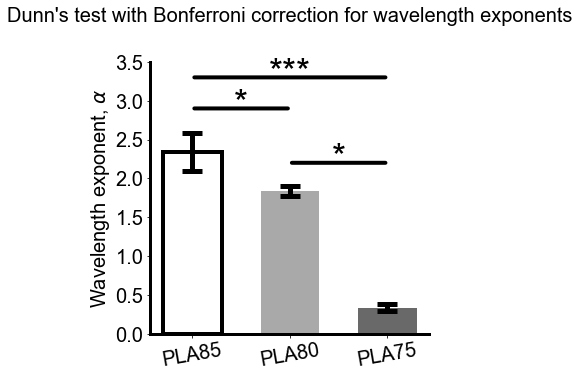

In [5]:
mtl.rcParams['legend.frameon'] = 'False'
rcParams['figure.figsize'] = 5, 5
rcParams['font.size'] = 14

average_pla85 = np.mean(pla85)
average_pla80 = np.mean(pla80)
average_pla75 = np.mean(pla75)

std_pla85 = np.std(pla85)
std_pla80 = np.std(pla80)
std_pla75 = np.std(pla75)

data = np.array([[average_pla85, std_pla85],
[average_pla80, std_pla80],
[average_pla75, std_pla75]])

fig, ax = plt.subplots()

labelsx = ['PLA85', 'PLA80', 'PLA75']
x = np.arange(len(labelsx))  # the label locations
plt.xticks(x, labelsx)
# tilt of the x labels
plt.xticks(fontsize=20, fontname='arial', rotation=10)
plt.yticks(fontsize=20, fontname='arial')

width = 0.6  # the width of the bars

colors = ['black', 'darkgray', 'dimgray']
labels_hist = ['PLA85', 'PLA80', 'PLA75']
hatches = [None, None, None]

# Figure construciton
rects1 = ax.bar(x, data[:,0], width, color=colors[:], edgecolor=None, label=labels_hist[:], linewidth=1.5, hatch = hatches[:])

# --- First bin customization ---------------------------
rects1[0].set_facecolor('white')       # Filling with white
rects1[0].set_edgecolor('black')       # Adding black frame
rects1[0].set_linewidth(4)             # Modifying frame thickness
# -------------------------------------------------------
    
plt.title("Dunn's test with Bonferroni correction for wavelength exponents", fontsize=20, fontname='arial', pad=40)

plt.ylabel('Wavelength exponent, $\mathit{\\alpha}$', fontsize=20, fontname='arial')

plt.ylim(0, 3.5)

for i in range(len(labelsx)):
    plt.errorbar( i, data[i,0], yerr = data[i,1], ecolor='black', capsize=10, elinewidth=5, markeredgewidth=5)

# statistical annotation
def draw_brace(ax, xspan, yy, text):
    """Draws an annotated brace on the axes."""
    xmin, xmax = xspan
    xspan = xmax - xmin
    ax_xmin, ax_xmax = ax.get_xlim()
    xax_span = ax_xmax - ax_xmin

    ymin, ymax = ax.get_ylim()
    yspan = ymax - ymin
    resolution = int(xspan/xax_span*100)*2+1 # guaranteed uneven
    beta = 100./xax_span # the higher this is, the smaller the radius

    x = np.linspace(xmin, xmax, resolution)
    x_half = x[:int(resolution/2)+1]
    y_half_brace = (1/(1.+np.exp(-beta*(x_half-x_half[0])))
                    + 1/(1.+np.exp(-beta*(x_half-x_half[-1]))))
    y = np.concatenate((y_half_brace, y_half_brace[-2::-1]))
    y = yy + (.05*y - .01)*yspan # adjust vertical position

    ax.autoscale(False)
    ax.plot(x, y, color='none', lw=1)

    ax.text((xmax+xmin)/2., yy+.07*yspan, text, ha='center', va='bottom', size=36, fontname='arial')

import matplotlib.patches as mpatches

ax.annotate("",
            xy=(0, 3.3), xycoords='data',
            xytext=(2, 3.3), textcoords='data',
            arrowprops=dict(arrowstyle="-", connectionstyle="arc3", linewidth=4))
ax.annotate("",
            xy=(0, 2.9), xycoords='data',
            xytext=(1, 2.9), textcoords='data',
            arrowprops=dict(arrowstyle="-", connectionstyle="arc3", linewidth=4))
ax.annotate("",
            xy=(1, 2.2), xycoords='data',
            xytext=(2, 2.2), textcoords='data',
            arrowprops=dict(arrowstyle="-", connectionstyle="arc3", linewidth=4))

draw_brace(ax, (0, 2), 2.9, '***')
draw_brace(ax, (0, 1), 2.5, '*')
draw_brace(ax, (1, 2), 1.8, '*')

sns.despine(fig=None, ax=None, top=True, right=True, left=False, bottom=False, offset=None, trim=False)

plt.text(0.5, 0.7, '')

# Setting spines to save in tiff
ax.spines['left'].set_linewidth(3)
ax.spines['bottom'].set_linewidth(3)

plt.savefig('alpha_histogram.tiff', dpi=300, bbox_inches='tight', pad_inches=0.1)

plt.show()